# Bitcoin (BTC-USD) Data Preprocessing & Feature Engineering

This notebook performs automated data acquisition, cleaning, and comprehensive **Feature Engineering** on historical Bitcoin (`BTC-USD`) market data. 

### Key Categories of Engineered Features:
1. **Price Returns & Log Returns**: Multi-horizon percentage returns (1d, 3d, 7d, 14d, 30d) and log returns.
2. **Lag Features**: Past prices, returns, and volumes across multiple lag intervals (1, 2, 3, 5, 7, 14, 30 days).
3. **Trend & Moving Averages**: Simple Moving Averages (SMA) and Exponential Moving Averages (EMA) (7, 14, 30, 50, 200 days) & Moving Average Crossovers/Ratios.
4. **Volatility & Price Range Metrics**: Rolling standard deviations, Annualized Volatility, Average True Range (ATR-14), Bollinger Bands (Upper, Lower, Width, %B).
5. **Momentum Indicators**: Relative Strength Index (RSI-14), MACD (Line, Signal, Histogram), Stochastic Oscillator (%K, %D).
6. **Volume & Candlestick Dynamics**: Rolling Volume SMAs, Volume Surge Ratios, On-Balance Volume (OBV), High-Low range %, Upper/Lower Shadows, Candle Body %.
7. **Calendar & Cyclical Features**: Day of week, day of month, month, quarter, weekend indicators, and cyclical sine/cosine transformations.
8. **Supervised Target Variables**: 1-day ahead close price (`Target_Next_Close`), 1-day ahead return (`Target_Next_Return`), and binary direction classification (`Target_Direction`).


In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Plot aesthetics
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully.")


Libraries imported successfully.


## Step 1: Data Acquisition & Initial Inspection

In [2]:
# Fetch Bitcoin historical data from Yahoo Finance
ticker = "BTC-USD"
start_date = "2018-01-01"
end_date = "2026-01-01"

print(f"Downloading {ticker} data from {start_date} to {end_date}...")
btc = yf.download(ticker, start=start_date, end=end_date, interval="1d")

# Flatten MultiIndex columns if present (yfinance 0.2+)
if isinstance(btc.columns, pd.MultiIndex):
    btc.columns = btc.columns.get_level_values(0)

# Reorder standard OHLCV columns
btc = btc[['Open', 'High', 'Low', 'Close', 'Volume']].copy()

print(f"\nDataset Summary: Rows={btc.shape[0]}, Columns={btc.shape[1]}")
display(btc.head())



[*********************100%***********************]  1 of 1 completed


Dataset Summary: Rows=2922, Columns=5


Price,Open,High,Low,Close,Volume
Date,,,,,
2018-01-01,14112.200195,14112.200195,13154.700195,13657.200195,10291200000
2018-01-02,13625.000000,15444.599609,13163.599609,14982.099609,16846600192
2018-01-03,14978.200195,15572.799805,14844.500000,15201.000000,16871900160
2018-01-04,15270.700195,15739.700195,14522.200195,15599.200195,21783199744
2018-01-05,15477.200195,17705.199219,15202.799805,17429.500000,23840899072


## Step 2: Price Returns & Log Returns

In [3]:
df = btc.copy()

# Calculate simple returns across multiple time horizons
df['Return_1d'] = df['Close'].pct_change()
df['Return_3d'] = df['Close'].pct_change(3)
df['Return_7d'] = df['Close'].pct_change(7)
df['Return_14d'] = df['Close'].pct_change(14)
df['Return_30d'] = df['Close'].pct_change(30)

# Log return
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))

print("Price return features created:")
display(df[['Close', 'Return_1d', 'Return_7d', 'Log_Return']].head(10))


Price return features created:


Price,Close,Return_1d,Return_7d,Log_Return
Date,,,,
2018-01-01,13657.200195,NaN,NaN,NaN
2018-01-02,14982.099609,0.097011,NaN,0.092589
2018-01-03,15201.000000,0.014611,NaN,0.014505
2018-01-04,15599.200195,0.026196,NaN,0.025858
2018-01-05,17429.500000,0.117333,NaN,0.110945
2018-01-06,17527.000000,0.005594,NaN,0.005578
2018-01-07,16477.599609,-0.059873,NaN,-0.061741
2018-01-08,15170.099609,-0.079350,0.110777,-0.082675
2018-01-09,14595.400391,-0.037884,-0.025811,-0.038620


## Step 3: Lag Features

In [4]:
# Create price, return, and volume lags
lag_days = [1, 2, 3, 5, 7, 14, 30]

for lag in lag_days:
    df[f'Close_Lag_{lag}'] = df['Close'].shift(lag)
    df[f'Return_Lag_{lag}'] = df['Return_1d'].shift(lag)
    df[f'Volume_Lag_{lag}'] = df['Volume'].shift(lag)

print(f"Lag features generated for horizons: {lag_days}")


Lag features generated for horizons: [1, 2, 3, 5, 7, 14, 30]


## Step 4: Moving Averages & Trend Crossovers

In [5]:
ma_windows = [7, 14, 30, 50, 200]

for window in ma_windows:
    df[f'SMA_{window}'] = df['Close'].rolling(window=window).mean()
    df[f'EMA_{window}'] = df['Close'].ewm(span=window, adjust=False).mean()

# Trend Crossovers and Ratios
df['SMA_7_50_Ratio'] = df['SMA_7'] / df['SMA_50']
df['SMA_50_200_Ratio'] = df['SMA_50'] / df['SMA_200']
df['Close_EMA_14_Ratio'] = df['Close'] / df['EMA_14']

print("Moving average features created.")


Moving average features created.


## Step 5: Volatility & Price Range Metrics

In [6]:
# Rolling Volatility
df['Vol_7d'] = df['Return_1d'].rolling(7).std()
df['Vol_14d'] = df['Return_1d'].rolling(14).std()
df['Vol_30d'] = df['Return_1d'].rolling(30).std()
df['Annual_Vol_30d'] = df['Vol_30d'] * np.sqrt(365)

# Average True Range (ATR - 14 period)
tr1 = df['High'] - df['Low']
tr2 = (df['High'] - df['Close'].shift(1)).abs()
tr3 = (df['Low'] - df['Close'].shift(1)).abs()
tr = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
df['ATR_14'] = tr.rolling(14).mean()

# Bollinger Bands (20-day SMA, 2 Std Dev)
df['BB_Middle'] = df['Close'].rolling(20).mean()
df['BB_Std'] = df['Close'].rolling(20).std()
df['BB_Upper'] = df['BB_Middle'] + (df['BB_Std'] * 2)
df['BB_Lower'] = df['BB_Middle'] - (df['BB_Std'] * 2)
df['BB_Width'] = (df['BB_Upper'] - df['BB_Lower']) / df['BB_Middle']
df['BB_PctB'] = (df['Close'] - df['BB_Lower']) / (df['BB_Upper'] - df['BB_Lower'])

print("Volatility and Bollinger Band features created.")


Volatility and Bollinger Band features created.


## Step 6: Momentum Oscillators (RSI, MACD, Stochastic)

In [7]:
# 1. RSI (14 period)
delta = df['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(14).mean()
rs = gain / loss
df['RSI_14'] = 100 - (100 / (1 + rs))

# 2. MACD (12, 26, 9)
ema_12 = df['Close'].ewm(span=12, adjust=False).mean()
ema_26 = df['Close'].ewm(span=26, adjust=False).mean()
df['MACD'] = ema_12 - ema_26
df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']

# 3. Stochastic Oscillator (%K, %D - 14 period)
low_14 = df['Low'].rolling(14).min()
high_14 = df['High'].rolling(14).max()
df['Stoch_K'] = 100 * ((df['Close'] - low_14) / (high_14 - low_14))
df['Stoch_D'] = df['Stoch_K'].rolling(3).mean()

print("Momentum indicators (RSI, MACD, Stochastic) created.")


Momentum indicators (RSI, MACD, Stochastic) created.


## Step 7: Volume Dynamics & Candlestick Price Structure

In [8]:
# Volume features
df['Volume_SMA_7'] = df['Volume'].rolling(7).mean()
df['Volume_SMA_30'] = df['Volume'].rolling(30).mean()
df['Volume_Ratio'] = df['Volume'] / df['Volume_SMA_7']
df['OBV'] = (np.sign(df['Close'].diff()) * df['Volume']).fillna(0).cumsum()

# Candlestick Price Dynamics
df['High_Low_Pct'] = (df['High'] - df['Low']) / df['Close']
df['Upper_Shadow'] = (df['High'] - np.maximum(df['Open'], df['Close'])) / df['Close']
df['Lower_Shadow'] = (np.minimum(df['Open'], df['Close']) - df['Low']) / df['Close']
df['Body_Pct'] = (df['Close'] - df['Open']).abs() / df['Close']

print("Volume and Candlestick features created.")


Volume and Candlestick features created.


## Step 8: Temporal & Cyclical Features

In [9]:
df['Day_of_Week'] = df.index.dayofweek
df['Day_of_Month'] = df.index.day
df['Month'] = df.index.month
df['Quarter'] = df.index.quarter
df['Is_Weekend'] = (df.index.dayofweek >= 5).astype(int)

# Cyclical Sine/Cosine encodings
df['Sin_DayOfWeek'] = np.sin(2 * np.pi * df['Day_of_Week'] / 7.0)
df['Cos_DayOfWeek'] = np.cos(2 * np.pi * df['Day_of_Week'] / 7.0)
df['Sin_Month'] = np.sin(2 * np.pi * df['Month'] / 12.0)
df['Cos_Month'] = np.cos(2 * np.pi * df['Month'] / 12.0)

print("Calendar and Cyclical features created.")


Calendar and Cyclical features created.


## Step 9: Supervised Learning Targets

In [10]:
# Next day target variables for predictive models (LSTM, XGBoost, ARIMA)
df['Target_Next_Close'] = df['Close'].shift(-1)
df['Target_Next_Return'] = df['Return_1d'].shift(-1)
df['Target_Direction'] = (df['Target_Next_Return'] > 0).astype(int)

print("Supervised target variables created.")


Supervised target variables created.


## Step 10: Cleaning Missing Values & Data Verification

In [11]:
# Summary of NaNs before cleaning
null_counts = df.isnull().sum()
print("Features with missing values due to rolling windows/lags:")
print(null_counts[null_counts > 0].sort_values(ascending=False).head(15))

# Drop early NaN rows (due to 200-day SMA lookback) and last row (target is NaN for next day)
df_clean = df.dropna().copy()

print(f"\nOriginal shape: {df.shape}")
print(f"Cleaned dataset shape (after dropna): {df_clean.shape}")
print(f"Total features created: {df_clean.shape[1]}")

display(df_clean.head())


Features with missing values due to rolling windows/lags:
Price
SMA_50_200_Ratio    199
SMA_200             199
SMA_7_50_Ratio       49
SMA_50               49
Return_Lag_30        31
Volume_Lag_30        30
Annual_Vol_30d       30
Vol_30d              30
Close_Lag_30         30
Return_30d           30
Volume_SMA_30        29
SMA_30               29
BB_Lower             19
BB_Std               19
BB_Upper             19
dtype: int64

Original shape: (2922, 82)
Cleaned dataset shape (after dropna): (2722, 82)
Total features created: 82


Price,Open,High,Low,Close,Volume,Return_1d,Return_3d,Return_7d,Return_14d,Return_30d,...,Month,Quarter,Is_Weekend,Sin_DayOfWeek,Cos_DayOfWeek,Sin_Month,Cos_Month,Target_Next_Close,Target_Next_Return,Target_Direction
Date,,,,,,,,,,,,,,,,,,,,,
2018-07-19,7378.200195,7494.459961,7295.459961,7466.859863,5111629824,0.013035,0.107555,0.198762,0.124673,0.102943,...,7,3,0,0.433884,-0.900969,-0.5,-0.866025,7354.129883,-0.015097,0
2018-07-20,7467.399902,7594.669922,7323.259766,7354.129883,4936869888,-0.015097,0.004520,0.178915,0.101990,0.085232,...,7,3,0,-0.433884,-0.900969,-0.5,-0.866025,7419.290039,0.008860,1
2018-07-21,7352.720215,7437.640137,7262.410156,7419.290039,3726609920,0.008860,0.006581,0.182146,0.082013,0.102463,...,7,3,1,-0.974928,-0.222521,-0.5,-0.866025,7418.490234,-0.000108,0
2018-07-22,7417.799805,7537.950195,7383.819824,7418.490234,3695460096,-0.000108,-0.006478,0.166495,0.095161,0.219406,...,7,3,1,-0.781831,0.623490,-0.5,-0.866025,7711.109863,0.039445,1
2018-07-23,7414.709961,7771.500000,7409.100098,7711.109863,5132480000,0.039445,0.048541,0.143785,0.143785,0.251300,...,7,3,0,0.000000,1.000000,-0.5,-0.866025,8424.269531,0.092485,1


## Step 11: Feature Visualizations & Technical Analysis

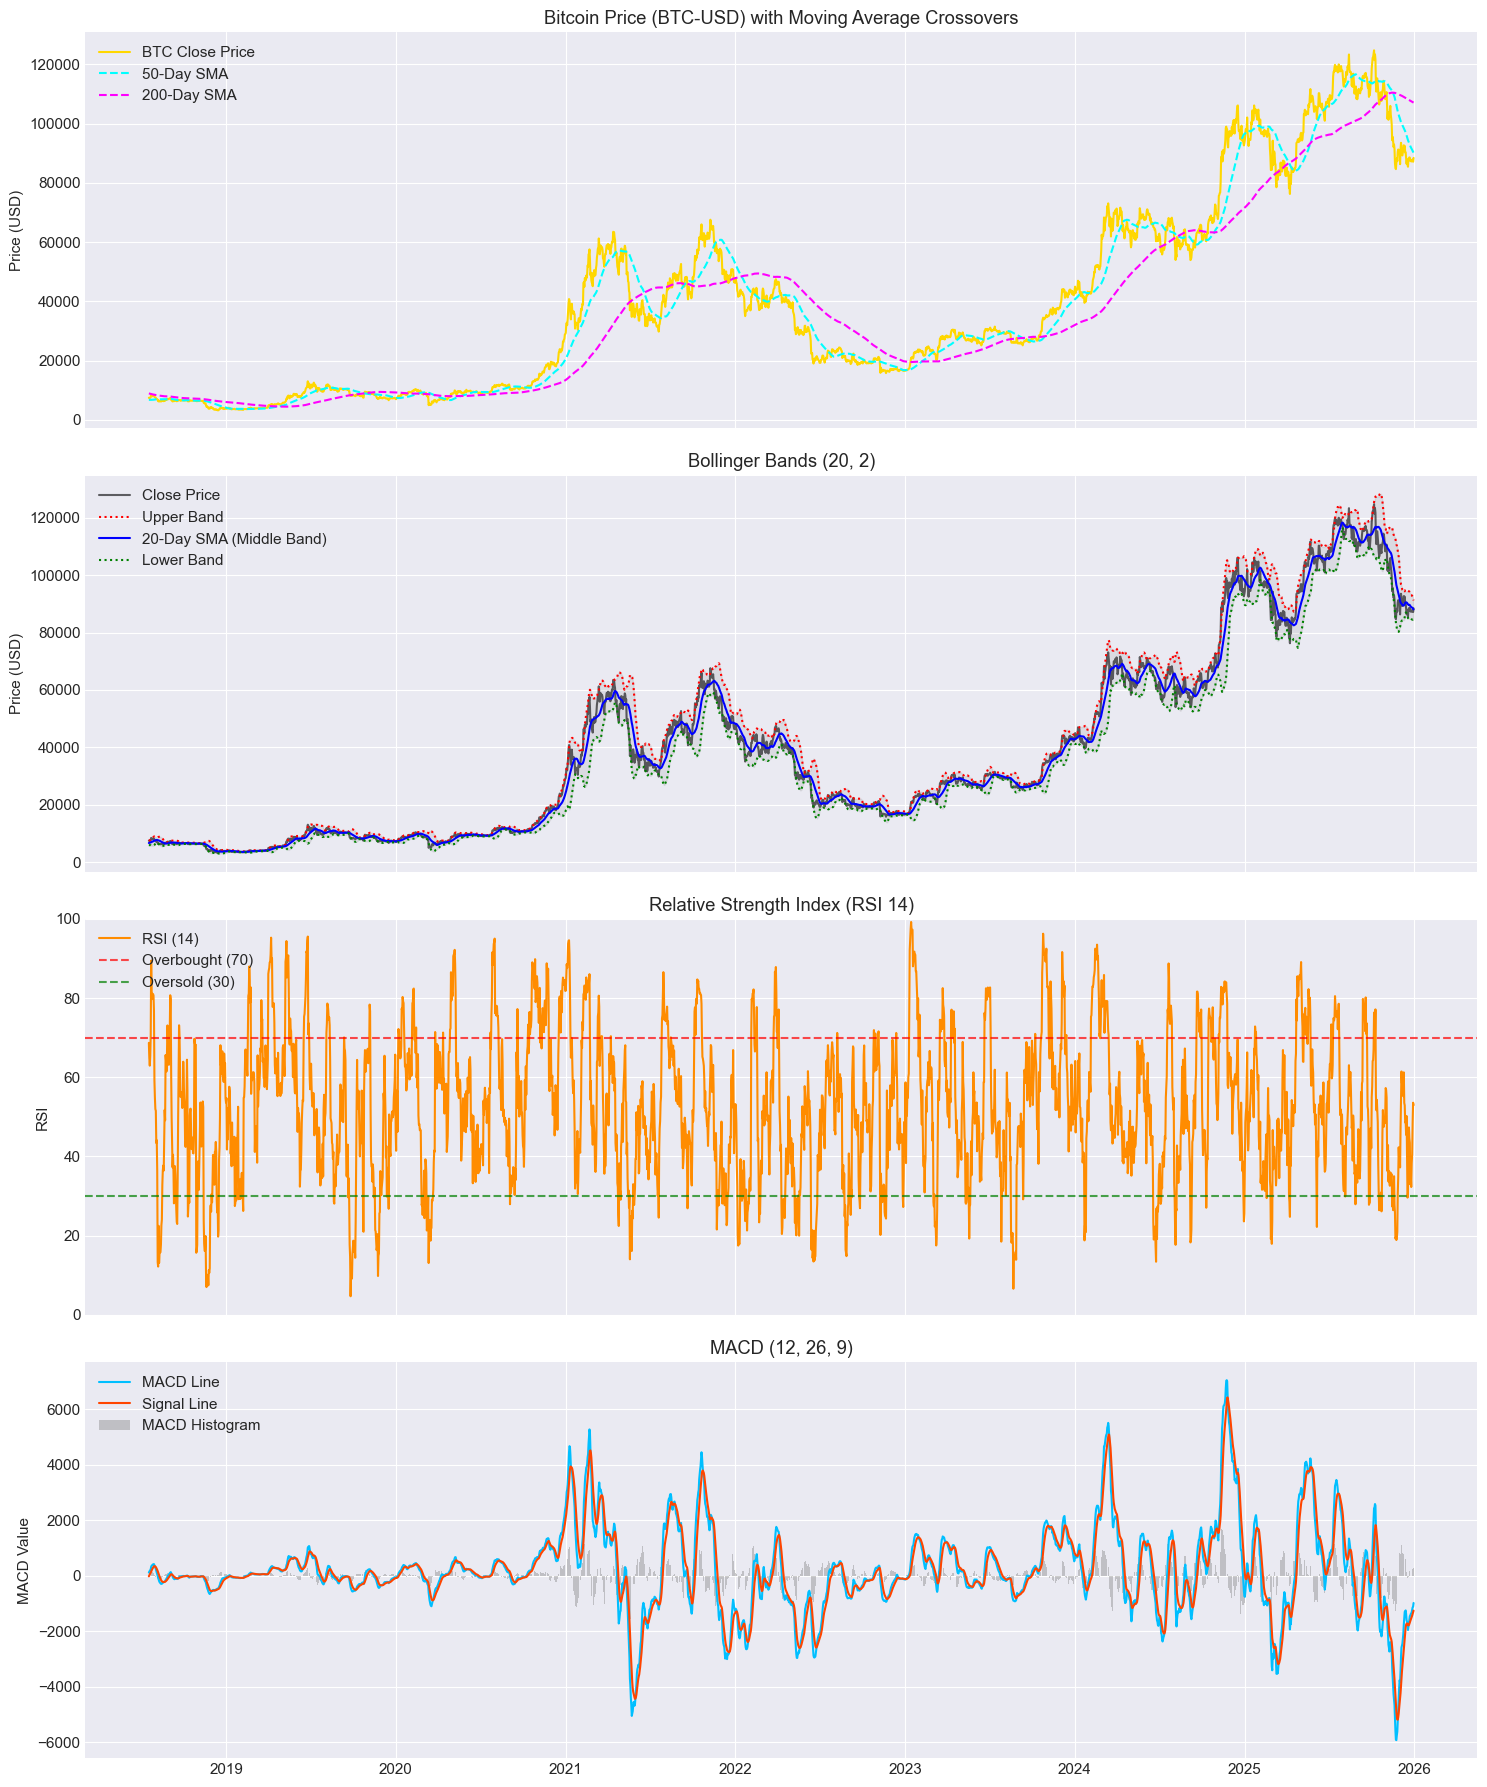

In [12]:
os.makedirs('plots', exist_ok=True)
fig, axes = plt.subplots(4, 1, figsize=(15, 18), sharex=True)

# 1. Price with SMA 50 & 200
axes[0].plot(df_clean.index, df_clean['Close'], label='BTC Close Price', color='gold', lw=1.5)
axes[0].plot(df_clean.index, df_clean['SMA_50'], label='50-Day SMA', color='cyan', linestyle='--')
axes[0].plot(df_clean.index, df_clean['SMA_200'], label='200-Day SMA', color='magenta', linestyle='--')
axes[0].set_title('Bitcoin Price (BTC-USD) with Moving Average Crossovers')
axes[0].set_ylabel('Price (USD)')
axes[0].legend(loc='upper left')

# 2. Bollinger Bands
axes[1].plot(df_clean.index, df_clean['Close'], label='Close Price', color='black', alpha=0.6)
axes[1].plot(df_clean.index, df_clean['BB_Upper'], label='Upper Band', color='red', linestyle=':')
axes[1].plot(df_clean.index, df_clean['BB_Middle'], label='20-Day SMA (Middle Band)', color='blue')
axes[1].plot(df_clean.index, df_clean['BB_Lower'], label='Lower Band', color='green', linestyle=':')
axes[1].fill_between(df_clean.index, df_clean['BB_Lower'], df_clean['BB_Upper'], color='gray', alpha=0.15)
axes[1].set_title('Bollinger Bands (20, 2)')
axes[1].set_ylabel('Price (USD)')
axes[1].legend(loc='upper left')

# 3. RSI (14)
axes[2].plot(df_clean.index, df_clean['RSI_14'], label='RSI (14)', color='darkorange')
axes[2].axhline(70, linestyle='--', color='red', alpha=0.7, label='Overbought (70)')
axes[2].axhline(30, linestyle='--', color='green', alpha=0.7, label='Oversold (30)')
axes[2].set_title('Relative Strength Index (RSI 14)')
axes[2].set_ylabel('RSI')
axes[2].set_ylim(0, 100)
axes[2].legend(loc='upper left')

# 4. MACD & Signal
axes[3].plot(df_clean.index, df_clean['MACD'], label='MACD Line', color='deepskyblue')
axes[3].plot(df_clean.index, df_clean['MACD_Signal'], label='Signal Line', color='orangered')
axes[3].bar(df_clean.index, df_clean['MACD_Hist'], label='MACD Histogram', color='gray', alpha=0.4)
axes[3].set_title('MACD (12, 26, 9)')
axes[3].set_ylabel('MACD Value')
axes[3].legend(loc='upper left')

plt.tight_layout()
plt.savefig('plots/btc_technical_indicators.png', dpi=300)
plt.show()


## Step 12: Feature Correlation Analysis

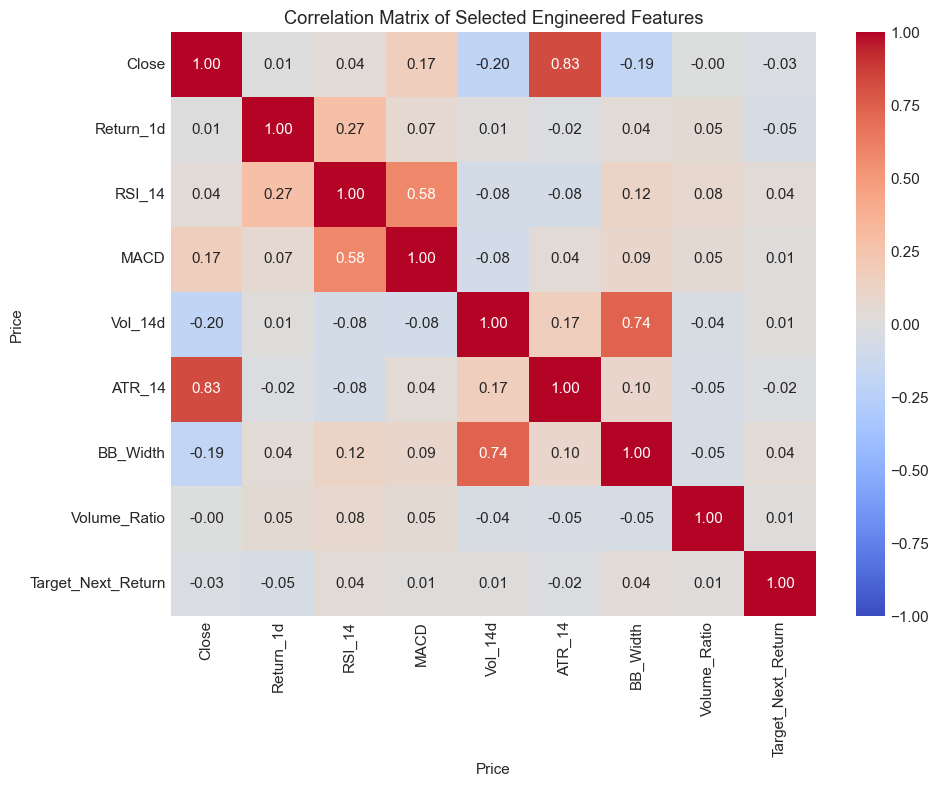

In [13]:
# Heatmap of key indicators
key_features = ['Close', 'Return_1d', 'RSI_14', 'MACD', 'Vol_14d', 'ATR_14', 'BB_Width', 'Volume_Ratio', 'Target_Next_Return']
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean[key_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Selected Engineered Features')
plt.tight_layout()
plt.savefig('plots/btc_correlation_heatmap.png', dpi=300)
plt.show()


## Step 13: Export Processed Dataset

In [14]:
os.makedirs('data', exist_ok=True)

# Save feature datasets
df_clean.to_csv('bitcoin_features.csv')
df_clean.to_csv('data/bitcoin_features.csv')

# Save updated bitcoin_data.csv for downstream models (ARIMA, LSTM, XGBoost)
df_clean.to_csv('bitcoin_data.csv')
df_clean.to_csv('data/bitcoin_data.csv')

print("Processed dataset successfully exported:")
print(" - bitcoin_features.csv (Root and data/)")
print(" - bitcoin_data.csv (Root and data/)")
print(f"Final Dataset Shape: {df_clean.shape}")


Processed dataset successfully exported:
 - bitcoin_features.csv (Root and data/)
 - bitcoin_data.csv (Root and data/)
Final Dataset Shape: (2722, 82)
